# 08 · Results Visualization

**Objective.** Regenerate every report figure from the saved CSVs, so the figures in
`report/figures/` are always reproducible from committed data (no manual plotting).

**Provenance & reproducibility**

- **Results shown here:** ⬇ **regenerated from saved CSVs** (Nov-17 results + the P1/P4 correlation tables). No training happens here.
- **Experimental setup:** Reads `results/*.csv`; writes PNG+PDF into `figures/` and `report/figures/`.
- **Implementation:** `notebooks/make_figures.py` (matplotlib/seaborn).
- **Original code:** pure plotting of committed results; the numbers originate from the Nov-17 runs (archived pipeline: `archive/cnn_experiments_original_monolithic.ipynb`).
- **Reproduce:** Run the cell (CPU, a few seconds).

In [1]:
# --- project setup: portable across local / Google Drive / fresh Colab ---
import os, sys

def find_project_root(marker="src"):
    # 1) walk up from the current directory (local checkout or Drive upload)
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, marker)):
            return p
        p = os.path.dirname(p)
    # 2) common Colab upload locations
    for c in ("/content/soil_moisture_research",
              "/content/drive/MyDrive/soil_moisture_research"):
        if os.path.isdir(os.path.join(c, marker)):
            return c
    raise FileNotFoundError(
        "Could not find the project root (a folder containing 'src/').\n"
        "Upload the whole soil_moisture_research/ folder to Drive/Colab and "
        "open this notebook from inside notebooks/.")

ROOT = find_project_root()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
print("project root set ->", os.path.basename(ROOT))  # portable: no absolute path

project root set -> soil_moisture_research


In [2]:
import runpy, os
# the figure script lives alongside the notebooks as a module
runpy.run_path('notebooks/make_figures.py', run_name='__main__')
print('regenerated figures in figures/ and report/figures/')

saved fig_p1_lag_correlation


saved fig_p4_lag_depth
saved fig_rmse_vs_horizon


saved fig_feature_importance_heatmap
saved fig_feature_by_station


saved fig_loss_curves
ALL FIGS DONE
regenerated figures in figures/ and report/figures/


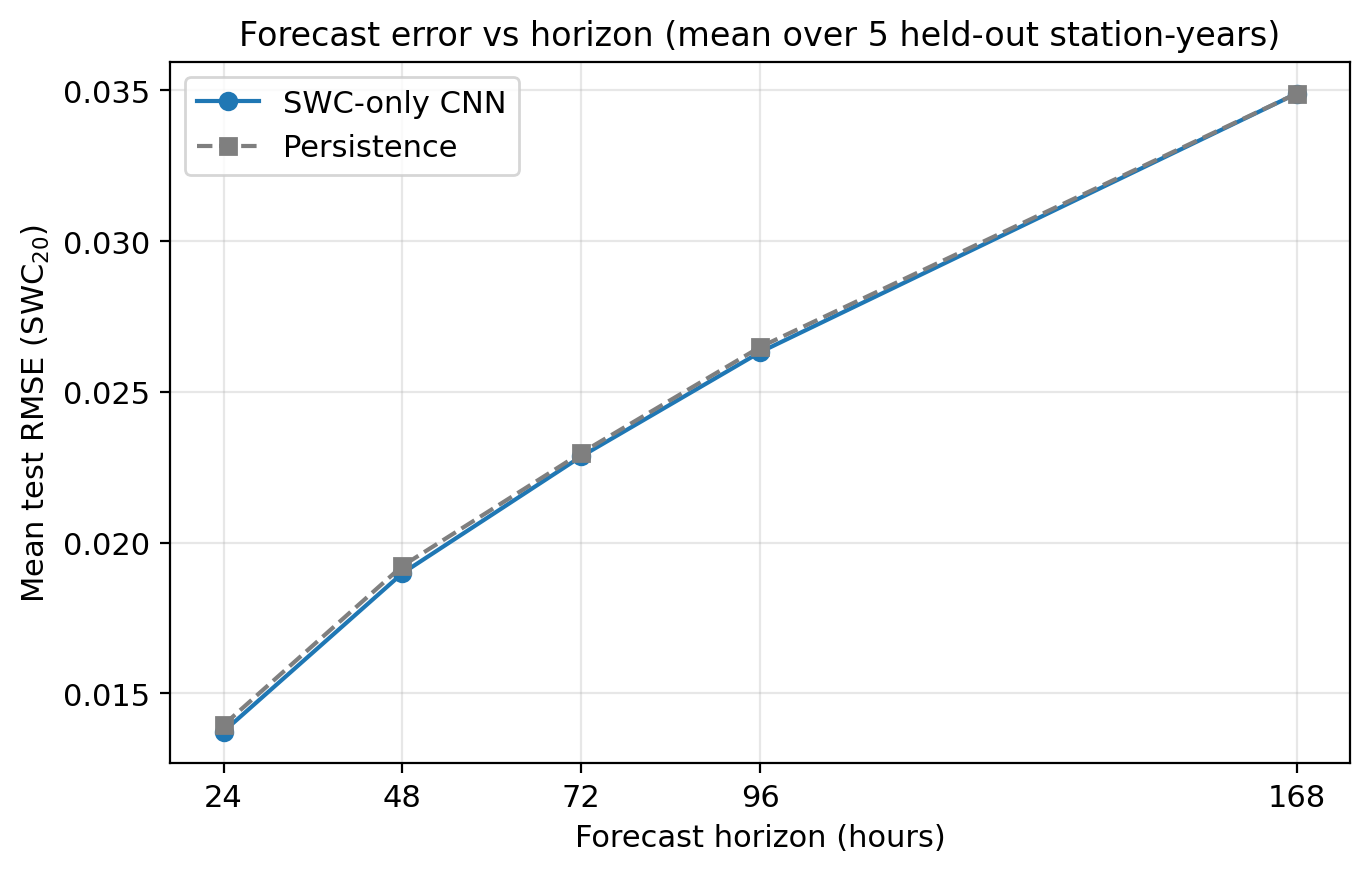

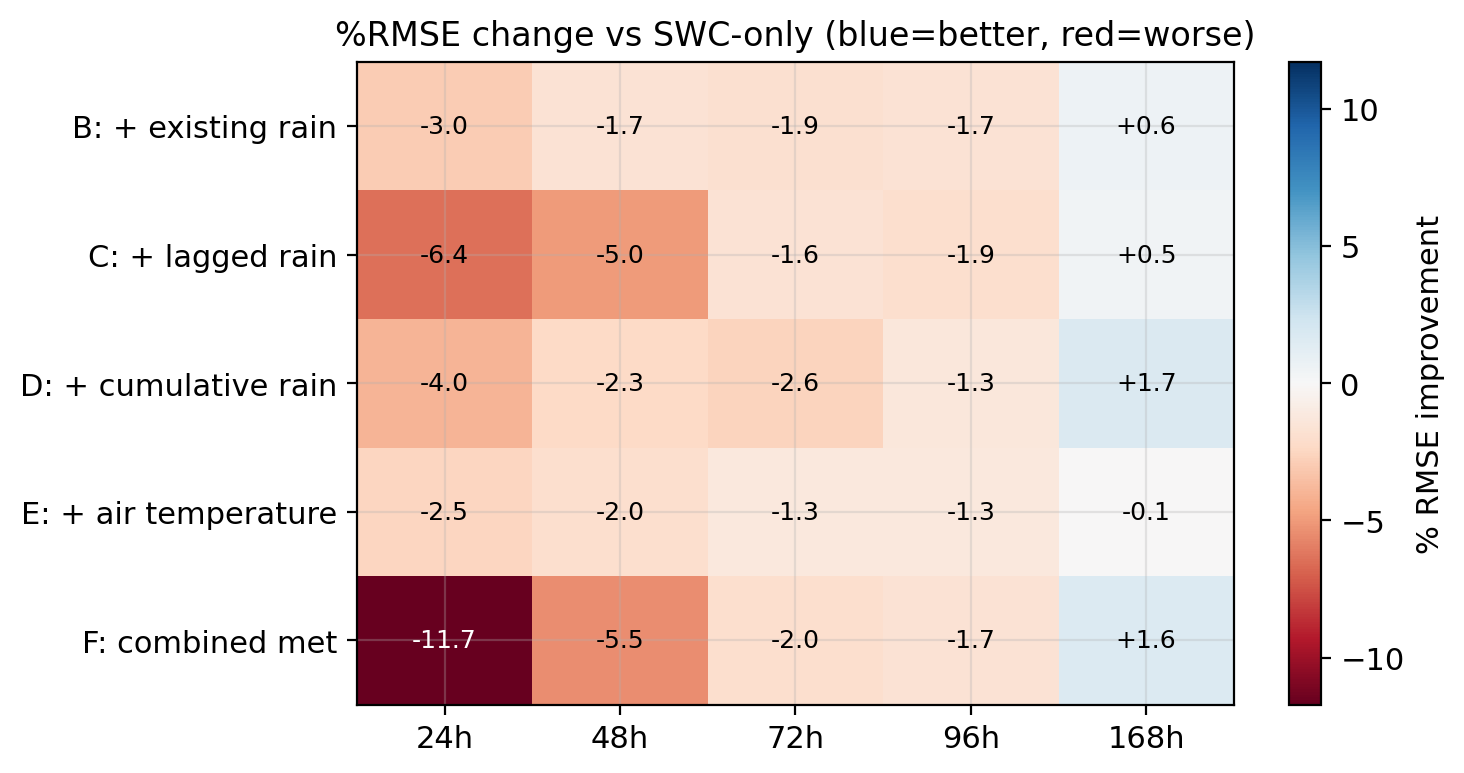

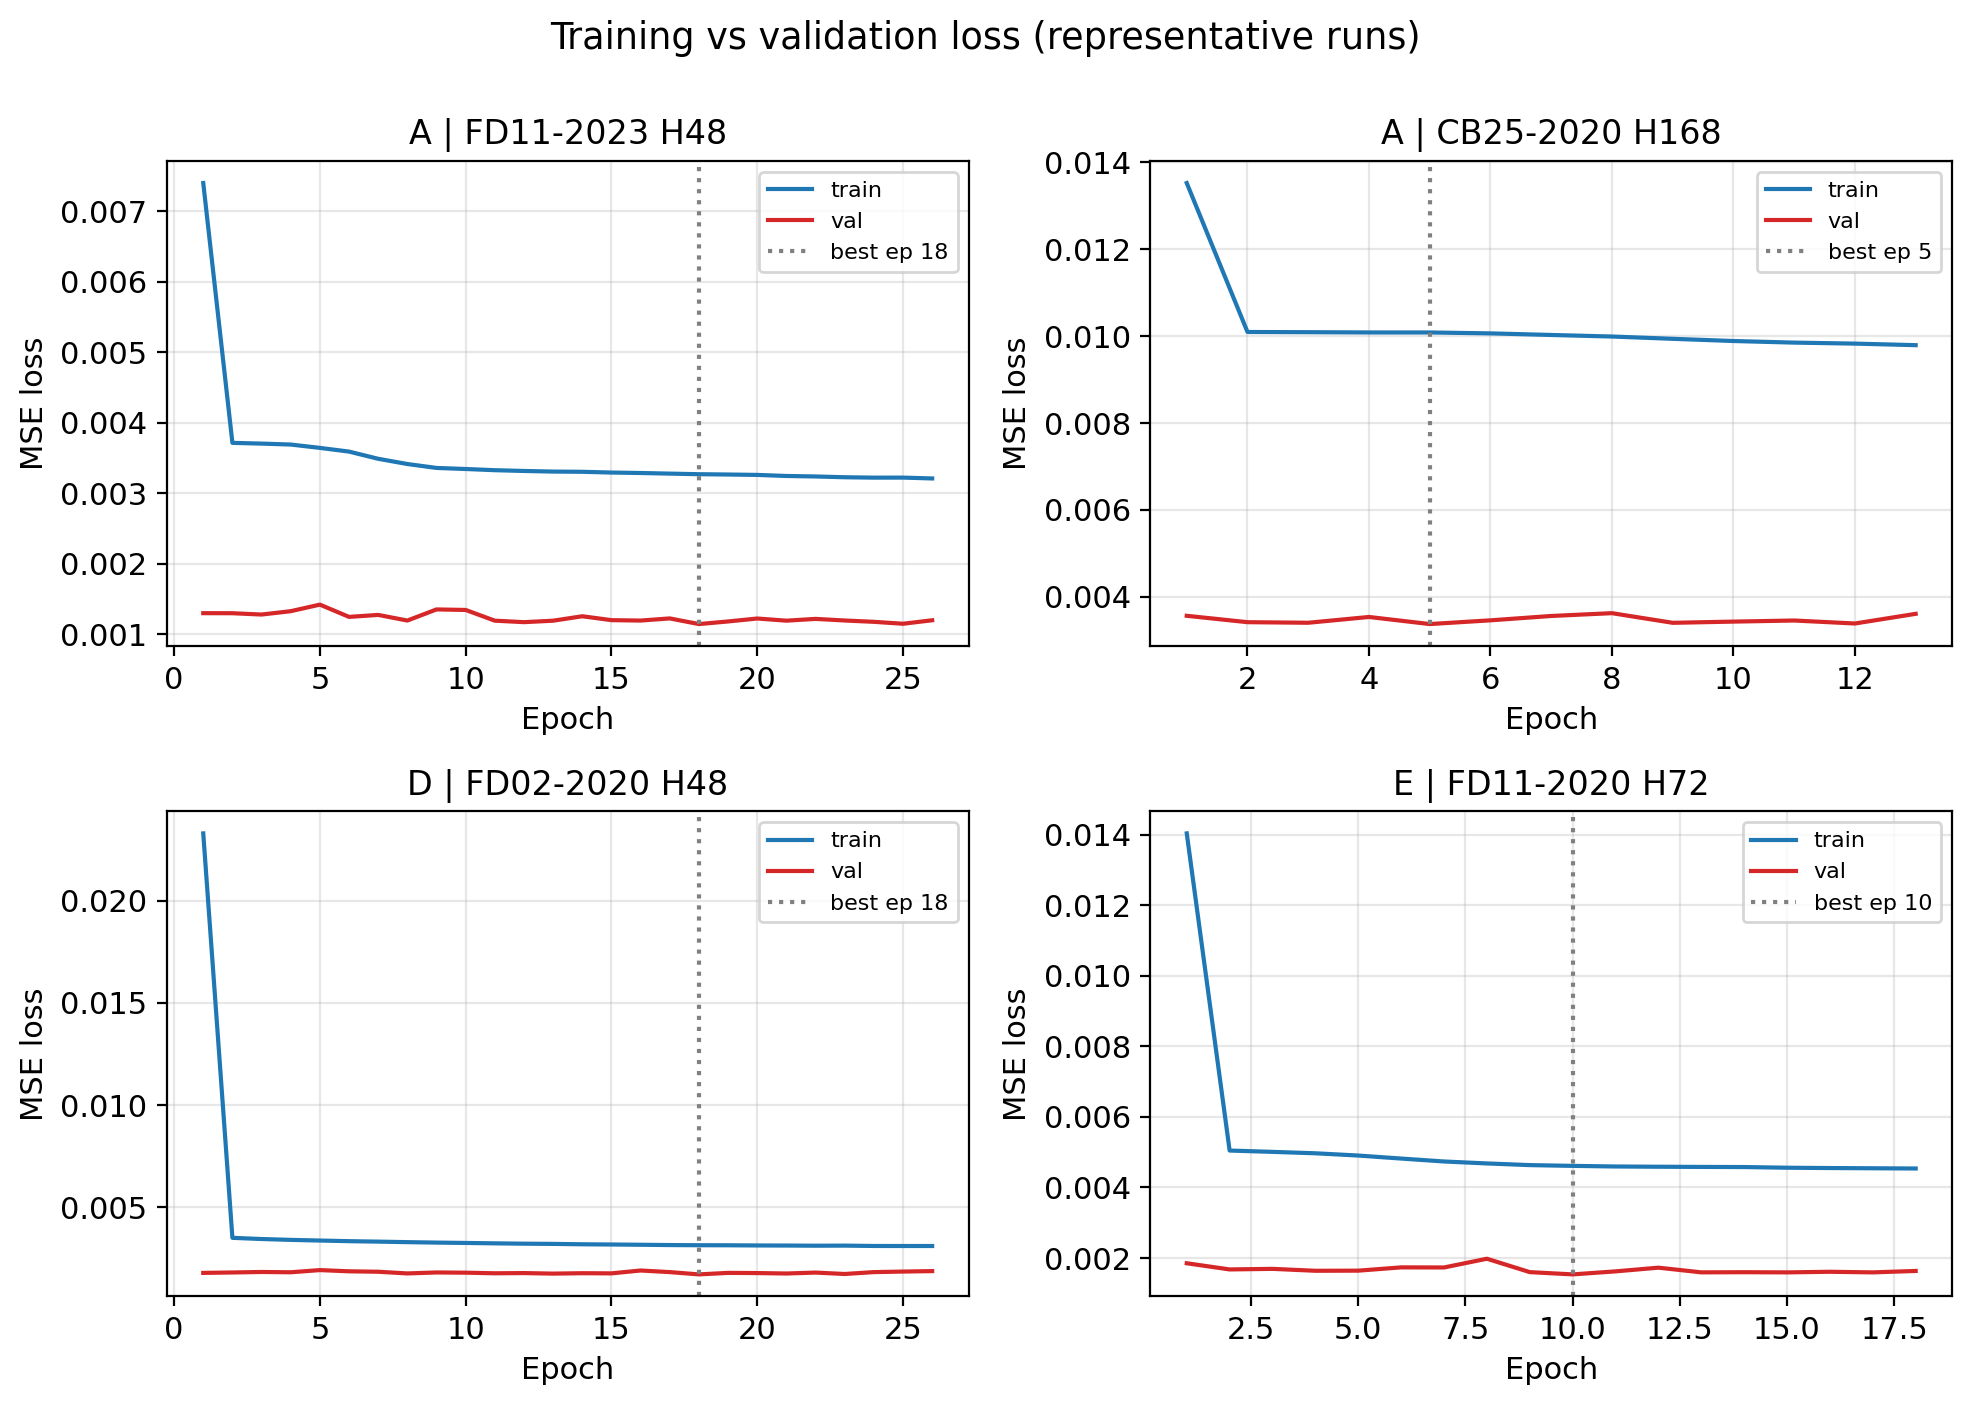

In [3]:
from IPython.display import Image, display
for f in ['fig_rmse_vs_horizon','fig_feature_importance_heatmap','fig_loss_curves']:
    display(Image(f'figures/{f}.png'))